# Predicció 2026 — ETS Additiu

ETS Additiu és el model guanyador del benchmark: WFV MASE=1.01 (1r lloc empatat amb l'Ensemble, però amb molta menys complexitat). Ara que tenim el 2025 real validat, entrenem el model sobre la **sèrie completa de 108 mesos (2017-01 → 2025-12)** i generem les prediccions mensuals per a **2026 (h=12)**.

Anàlisi complerta:
1. **Paràmetres del model** per a cada tecnologia (α, β, γ calibrats sobre 108 mesos).
2. **Prediccions mensuals 2026** amb intervals de confiança al 95% (bootstrap, 500 simulacions).
3. **Visualització per tecnologia** — grid 4×2 amb historial + previsió + banda IC.
4. **Mercat total 2026** — sèrie temporal i distribució mensual 2025 vs 2026.
5. **Mix tecnològic 2021–2026** — quotes i composició del mercat.
6. **Creixement interanual (YoY)** — 2023→2024→2025→2026.
7. **Conclusions** — on va el mercat de vehicle electrificat a Catalunya el 2026.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES  = TECNOLOGIES_MODELITZABLES + ['Total']
TECHS_NO_TOT = TECNOLOGIES_MODELITZABLES
H            = 12
MONTHS_CA    = ['Gen', 'Feb', 'Mar', 'Abr', 'Mai', 'Jun',
                 'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Des']
COLORS_TECH  = {
    'Elèctric':                    '#2166ac',
    'Gasolina Mild Hybrid':        '#74add1',
    'Gasolina/Elèctric':           '#f46d43',
    'Gasolina/Elèctric Endollable':'#fdae61',
    'Diesel Mild Hybrid':          '#a6d96a',
    'Diesel/Elèctric Endollable':  '#1a9641',
}
COLOR_HIST = '#2c7bb6'
COLOR_FC   = '#d73027'

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
pivot_full  = pd.concat([pivot_train, pivot_test]).sort_index()

print('Historial complet per a entrenament:')
print(f'  {pivot_full.index[0].date()} → {pivot_full.index[-1].date()} ({len(pivot_full)} mesos)')
print(f'  Train (2017–2024): {len(pivot_train)} mesos  |  Test (2025): {len(pivot_test)} mesos')
print(f'\nTecnologies: {TECNOLOGIES}')

Historial complet per a entrenament:
  2017-01-01 → 2025-12-01 (108 mesos)
  Train (2017–2024): 96 mesos  |  Test (2025): 12 mesos

Tecnologies: ['Elèctric', 'Gasolina Mild Hybrid', 'Gasolina/Elèctric', 'Gasolina/Elèctric Endollable', 'Diesel Mild Hybrid', 'Diesel/Elèctric Endollable', 'Total']


---
## 1. Entrenament sobre la sèrie completa (2017–2025)

Per generar les prediccions 2026 del model guanyador, entrenem ETS(add,add,add) sobre els **108 mesos complets** (2017-01 → 2025-12), incloent el 2025 que durant el benchmark era el test set. Incorporar el 2025 real és essencial: és l'any amb la pujada més gran (+34% YoY) i conté informació molt valuosa sobre el nou nivell del mercat.

Els paràmetres α (nivell), β (tendència) i γ (estacional) s'optimitzen per màxima versemblança sobre cada sèrie completa. La taula resultant revela tres règims de calibratge:

- **α alt (>0.3):** Gasolina/Elèctric Endollable, Diesel Mild Hybrid, Diesel/Elèctric Endollable. El model s'adapta ràpidament als canvis recents de nivell. Esperable per a sèries de creixement accelerat o irregular.
- **α baix (<0.2):** Gasolina Mild Hybrid, Gasolina/Elèctric, Total. L'actualització del nivell és gradual; el model pon més l'historial llarg.
- **α=β=γ=0 (Elèctric):** cas extrem on l'optimitzador descarta el suavitzat per complet i treballa amb una tendència lineal + estacionalitat fixos determinats per la descomposició inicial. Això passa quan la dinàmica de la sèrie és massa irregular per als supòsits additius d'ETS: la gran variabilitat interanual d'Elèctric (8.1% el 2023→2024, +52.9% el 2024→2025) penalitza qualsevol actualització incremental. La conseqüència directa és que el pic del 2025 **no s'absorbeix** en la previsió del 2026.

In [3]:
def fit_ets_additiu(series: pd.Series):
    s = series.copy()
    if isinstance(s.index, pd.DatetimeIndex) and s.index.freq is None:
        s = s.asfreq('MS')
    return ExponentialSmoothing(
        s, trend='add', seasonal='add', seasonal_periods=12
    ).fit(optimized=True, use_brute=False)

fitted_models = {}
param_rows    = []

for tech in TECNOLOGIES:
    series = pivot_full[tech].dropna()
    fitted = fit_ets_additiu(series)
    fitted_models[tech] = fitted
    p = fitted.params
    param_rows.append({
        'Tecnologia':    tech,
        'α (nivell)':    round(p['smoothing_level'], 3),
        'β (tendència)': round(p.get('smoothing_trend', float('nan')), 3),
        'γ (estacional)':round(p['smoothing_seasonal'], 3),
        'AIC':           round(fitted.aic, 1),
        'BIC':           round(fitted.bic, 1),
    })

df_params = pd.DataFrame(param_rows).set_index('Tecnologia')
print('Paràmetres ETS Additiu — entrenament sobre 108 mesos (2017–2025):')
display(df_params)

Paràmetres ETS Additiu — entrenament sobre 108 mesos (2017–2025):


,α (nivell),β (tendència),γ (estacional),AIC,BIC
Tecnologia,,,,,
Elèctric,0.000,0.000,0.000,1270.1,1313.0
Gasolina Mild Hybrid,0.232,0.000,0.336,1161.1,1204.0
Gasolina/Elèctric,0.105,0.105,0.000,1193.9,1236.8
Gasolina/Elèctric Endollable,0.549,0.000,0.000,1078.4,1121.3
Diesel Mild Hybrid,0.473,0.000,0.000,860.2,903.1
Diesel/Elèctric Endollable,0.305,0.000,0.000,528.1,571.0
Total,0.139,0.139,0.174,1449.3,1492.2


---
## 2. Prediccions mensuals 2026

Generem les prediccions puntuals i els **intervals de confiança al 95%** via simulació bootstrap (500 repeticions). Per cada tecnologia, la simulació mostra la distribució de trajectòries possibles als 12 mesos vista, capturant la incertesa estocàstica de la sèrie. Si la versió de statsmodels no admet bootstrap, es fa servir un interval analític basat en la desviació estàndard dels residus (σ·√h).

In [4]:
FC_MONTHS = pd.date_range('2026-01-01', periods=H, freq='MS')

forecast_rows = []
for tech in TECNOLOGIES:
    fitted = fitted_models[tech]
    fc     = fitted.forecast(H)

    try:
        sims  = fitted.simulate(nsimulations=H, repetitions=500,
                                error='add', random_errors='bootstrap')
        ci_lo = np.maximum(np.percentile(sims, 2.5,  axis=1), 0)
        ci_hi = np.percentile(sims, 97.5, axis=1)
    except Exception:
        sigma = np.std(fitted.resid)
        ci_lo = np.maximum(fc.values - 1.96 * sigma * np.sqrt(np.arange(1, H + 1)), 0)
        ci_hi = fc.values + 1.96 * sigma * np.sqrt(np.arange(1, H + 1))

    for i, date in enumerate(FC_MONTHS):
        forecast_rows.append({
            'Tecnologia': tech,
            'date':       date,
            'predicted':  max(float(fc.iloc[i]), 0),
            'ci_lower':   float(ci_lo[i]),
            'ci_upper':   float(ci_hi[i]),
        })

df_fc = pd.DataFrame(forecast_rows)
df_fc['date'] = pd.to_datetime(df_fc['date'])

fc_tot = df_fc[df_fc['Tecnologia'] == 'Total']['predicted'].sum()
re_tot = pivot_test['Total'].sum()
print(f'Prediccions generades: {len(df_fc)} registres ({H} mesos × {len(TECNOLOGIES)} tecnologies)')
print(f'\nTotal 2025 (real):       {re_tot:.0f} unitats')
print(f'Total 2026 (previsió):   {fc_tot:.0f} unitats')
print(f'YoY 2025 → 2026:         {(fc_tot - re_tot) / re_tot * 100:+.1f}%')

Prediccions generades: 84 registres (12 mesos × 7 tecnologies)

Total 2025 (real):       96175 unitats
Total 2026 (previsió):   120504 unitats
YoY 2025 → 2026:         +25.3%


In [5]:
# Taula mensual: files = mesos, columnes = tecnologies
pivot_fc = (df_fc.pivot(index='date', columns='Tecnologia', values='predicted')
            [TECNOLOGIES].round(0).astype(int))
pivot_fc.index = MONTHS_CA
print('Prediccions mensuals 2026 — ETS Additiu (unitats):')
display(pivot_fc)

# Resum anual comparatiu
annual_fc   = df_fc.groupby('Tecnologia')['predicted'].sum().loc[TECNOLOGIES]
annual_2025 = pd.Series({t: pivot_test[t].sum()  for t in TECNOLOGIES})
annual_2024 = pd.Series({t: pivot_train[t].loc['2024'].sum() for t in TECNOLOGIES})

df_annual = pd.DataFrame({
    '2024 (real)':     annual_2024.round(0).astype(int),
    '2025 (real)':     annual_2025.round(0).astype(int),
    '2026 (previsió)': annual_fc.round(0).astype(int),
    'YoY 24→25 (%)':   ((annual_2025 - annual_2024) / annual_2024 * 100).round(1),
    'YoY 25→26 (%)':   ((annual_fc   - annual_2025) / annual_2025 * 100).round(1),
}).loc[TECNOLOGIES]

print('\nResum anual comparatiu:')
display(df_annual)

Prediccions mensuals 2026 — ETS Additiu (unitats):


Tecnologia,Elèctric,Gasolina Mild Hybrid,Gasolina/Elèctric,Gasolina/Elèctric Endollable,Diesel Mild Hybrid,Diesel/Elèctric Endollable,Total
Gen,1513,2106,2708,1450,251,51,8738
Feb,1506,2176,2770,1481,249,48,9030
Mar,1717,2429,2757,1485,272,51,9585
Abr,1382,2163,2624,1483,261,51,8943
Mai,1452,2533,2964,1601,267,51,9877
Jun,1679,2592,3057,1642,287,50,10424
Jul,1782,2440,3259,1656,312,54,10764
Ago,1480,1862,2702,1469,248,48,9130
Set,1670,2338,2901,1583,285,53,10239
Oct,1658,2665,3215,1660,316,54,11006



Resum anual comparatiu:


,2024 (real),2025 (real),2026 (previsió),YoY 24→25 (%),YoY 25→26 (%)
Elèctric,13401,20495,19426,52.9,-5.2
Gasolina Mild Hybrid,21135,25789,28476,22.0,10.4
Gasolina/Elèctric,25810,30300,35600,17.4,17.5
Gasolina/Elèctric Endollable,7739,15606,18849,101.7,20.8
Diesel Mild Hybrid,3281,3407,3385,3.8,-0.6
Diesel/Elèctric Endollable,391,526,623,34.5,18.4
Total,71760,96175,120504,34.0,25.3


---
## 3. Visualització per tecnologia

Per a cada tecnologia: últims 36 mesos d'historial real (fins a desembre 2025) + prediccions 2026 amb banda d'incertesa al 95%. El títol de cada subplot indica la previsió anual 2026 i el creixement interanual esperat.

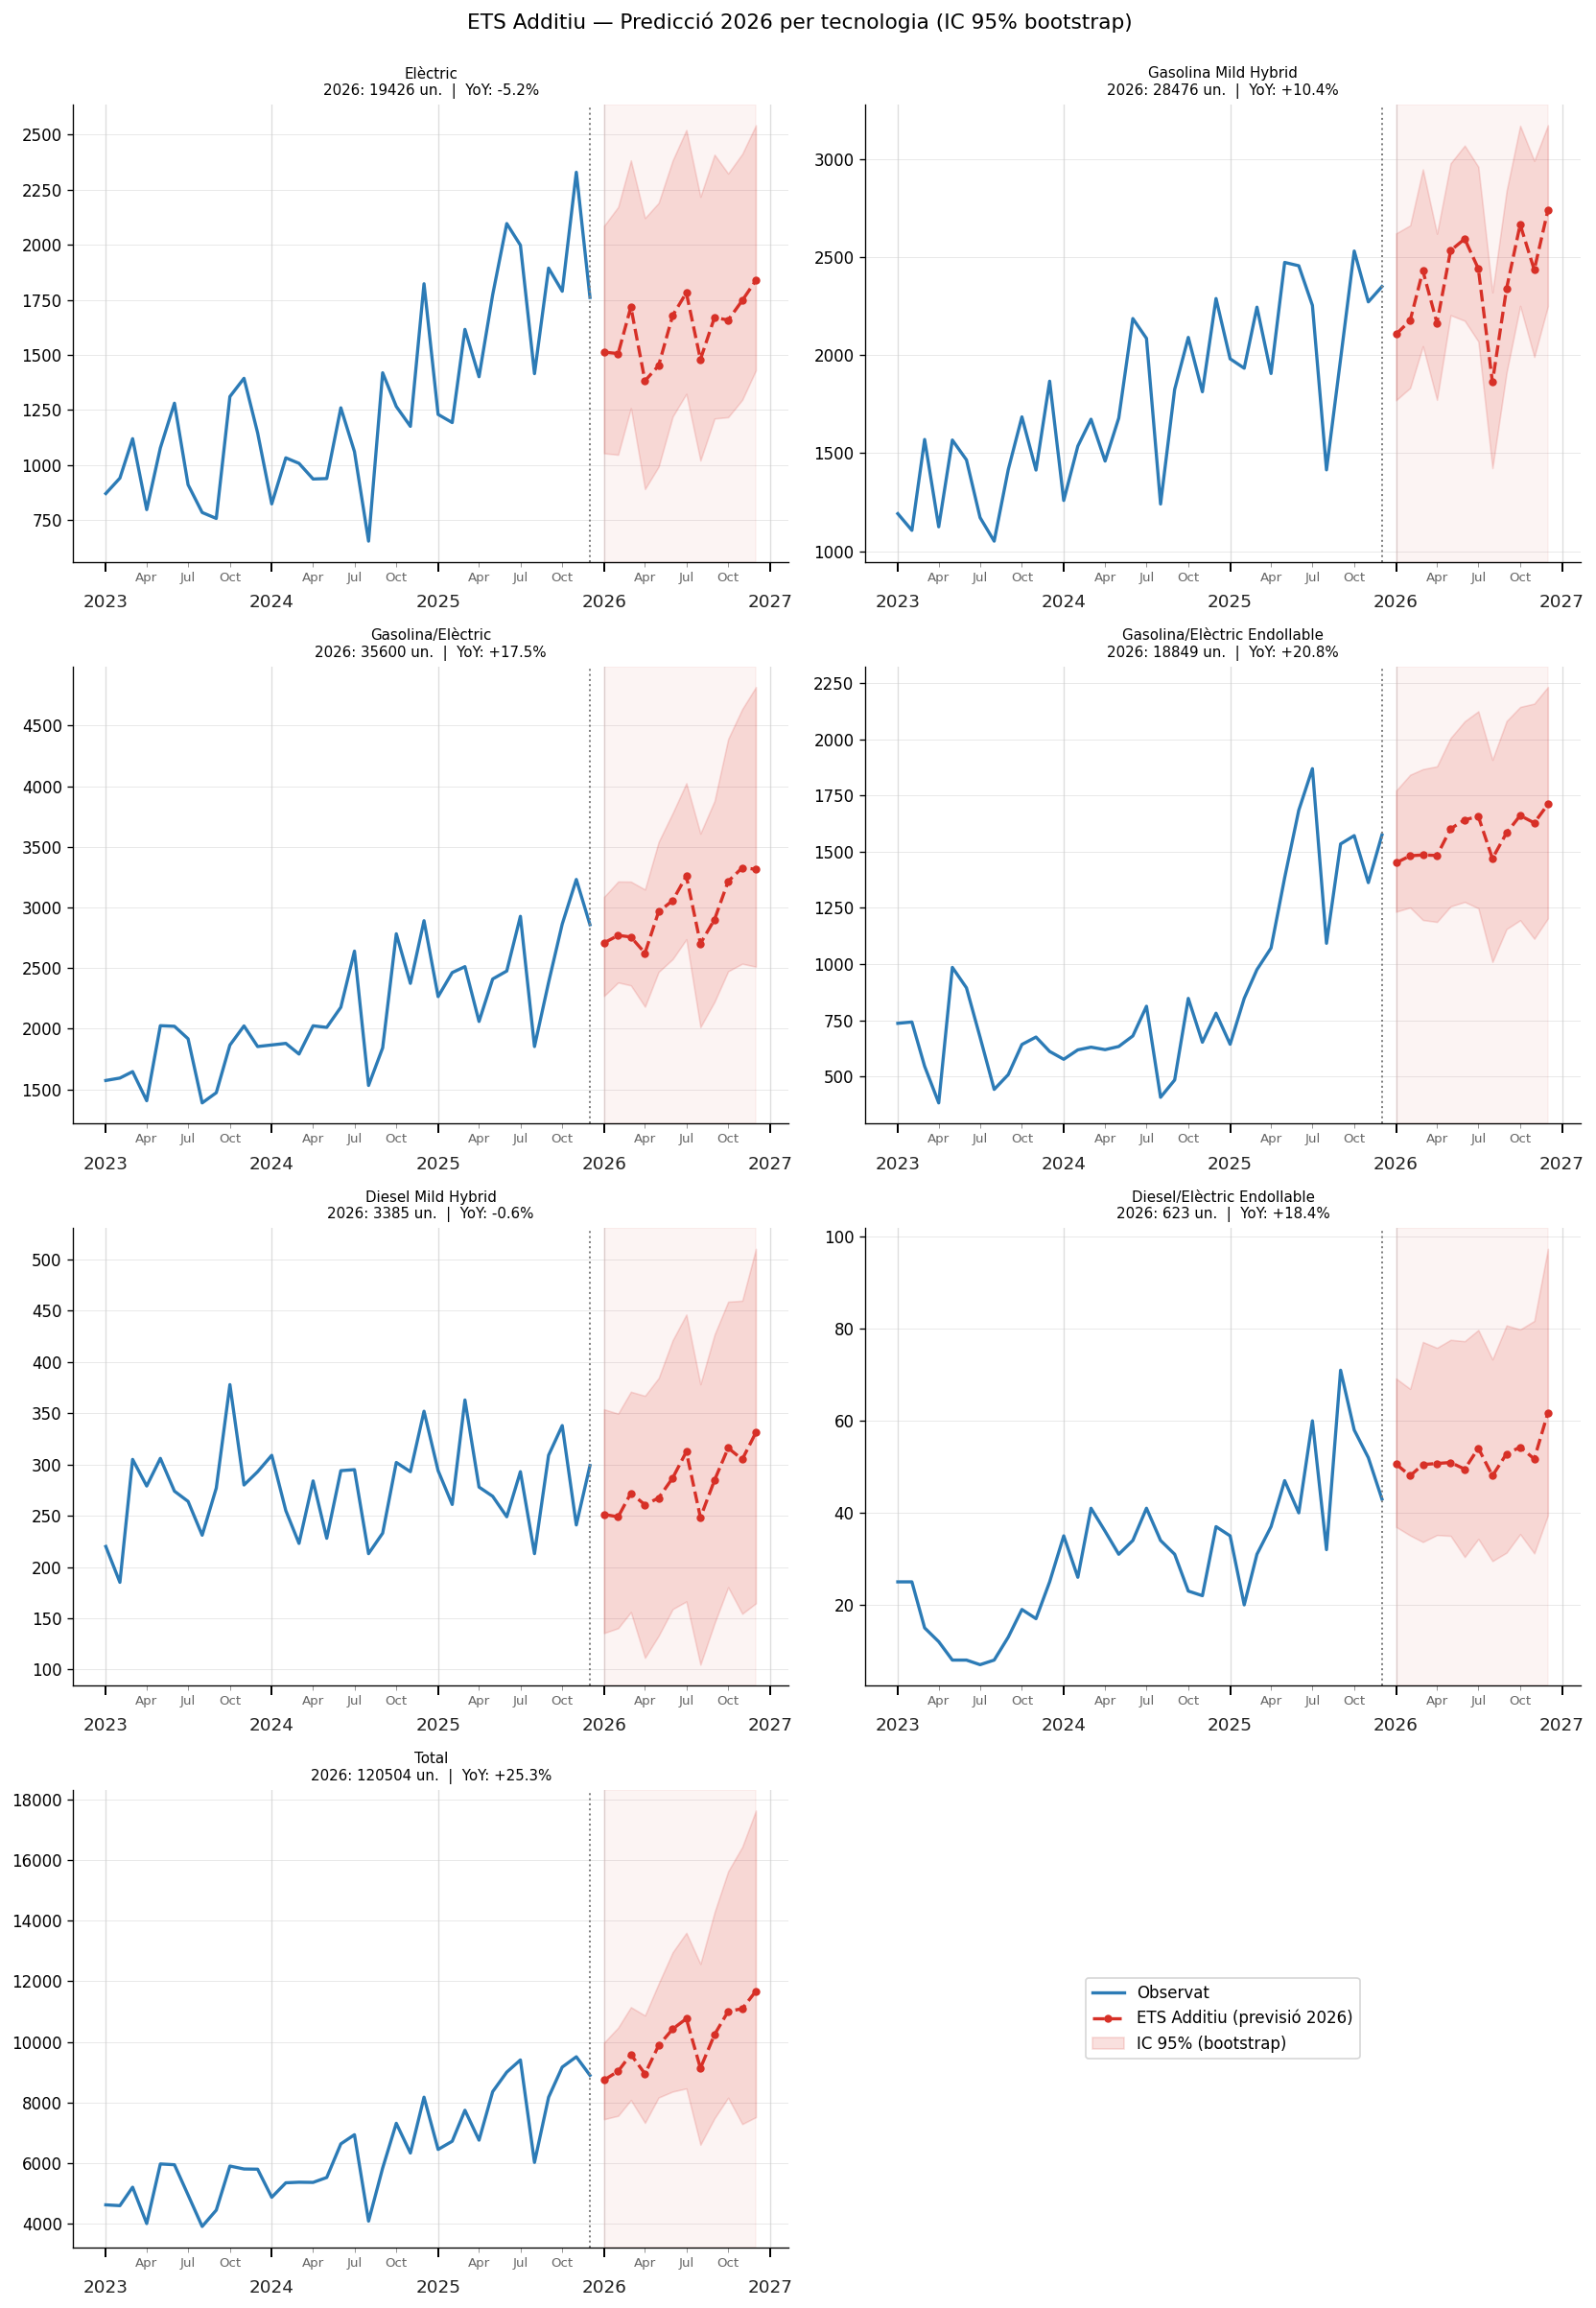

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()
TAIL = 36

for i, tech in enumerate(TECNOLOGIES):
    ax = axes_flat[i]

    hist = pivot_full[tech].iloc[-TAIL:]
    ax.plot(hist.index, hist.values, color=COLOR_HIST, lw=2, label='Observat')
    ax.axvline(pivot_full.index[-1], color='gray', ls=':', lw=1.2)

    sub      = df_fc[df_fc['Tecnologia'] == tech].sort_values('date')
    dates_fc = pd.to_datetime(sub['date'])
    ax.plot(dates_fc, sub['predicted'], color=COLOR_FC, lw=2, ls='--',
            marker='o', ms=4, label='ETS Additiu (previsió 2026)')
    ax.fill_between(dates_fc, sub['ci_lower'], sub['ci_upper'],
                    color=COLOR_FC, alpha=0.15, label='IC 95% (bootstrap)')
    ax.axvspan(dates_fc.iloc[0], dates_fc.iloc[-1], alpha=0.05, color=COLOR_FC)

    fc_anual  = sub['predicted'].sum()
    real_2025 = pivot_test[tech].sum()
    yoy       = (fc_anual - real_2025) / real_2025 * 100
    ax.set_title(f'{tech}\n2026: {fc_anual:.0f} un.  |  YoY: {yoy:+.1f}%', fontsize=9)
    format_ts_ax(ax)

for j in range(len(TECNOLOGIES), len(axes_flat)):
    axes_flat[j].axis('off')
    if j == len(axes_flat) - 1:
        handles, labels = axes_flat[0].get_legend_handles_labels()
        axes_flat[j].legend(handles, labels, loc='center', fontsize=10)

plt.suptitle('ETS Additiu — Predicció 2026 per tecnologia (IC 95% bootstrap)',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_29_forecast_2026_per_tech.png', bbox_inches='tight')
plt.show()

---
## 4. Mercat total 2026

La sèrie Total agrega totes les tecnologies. El primer gràfic mostra l'historial dels últims 4 anys + la previsió 2026 amb banda de confiança. El segon compara la distribució mensual 2025 real vs 2026 prevista.

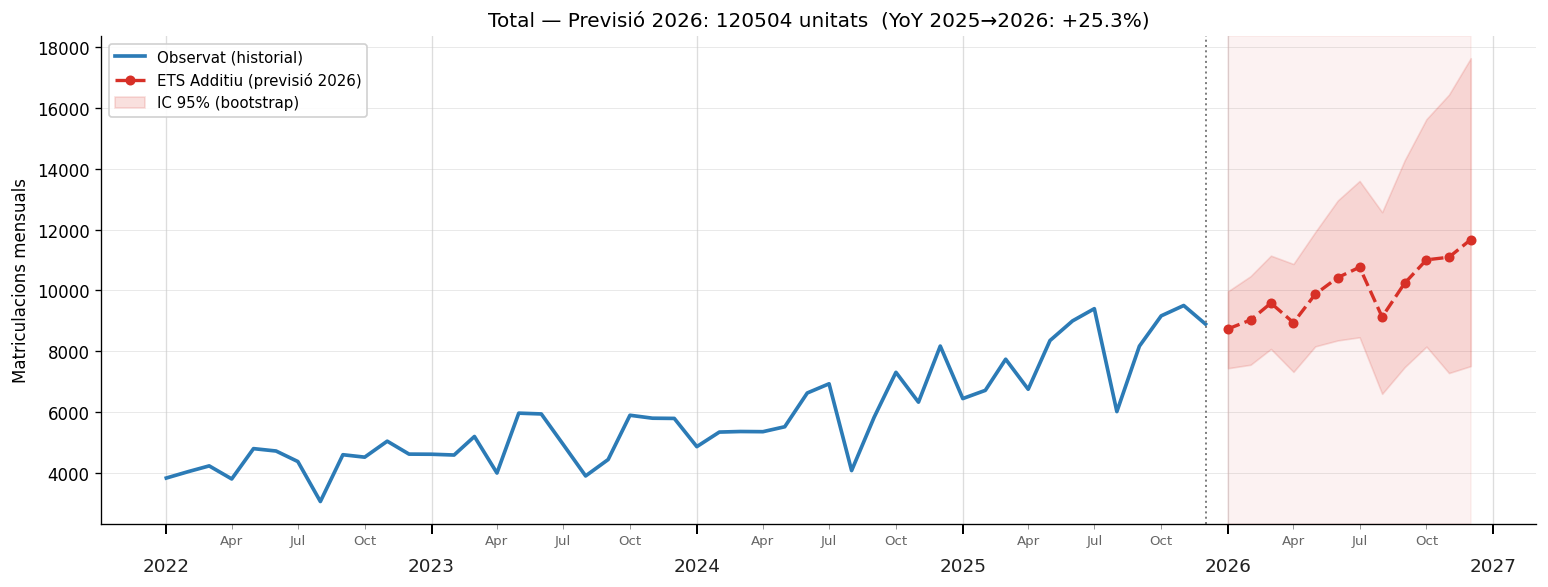

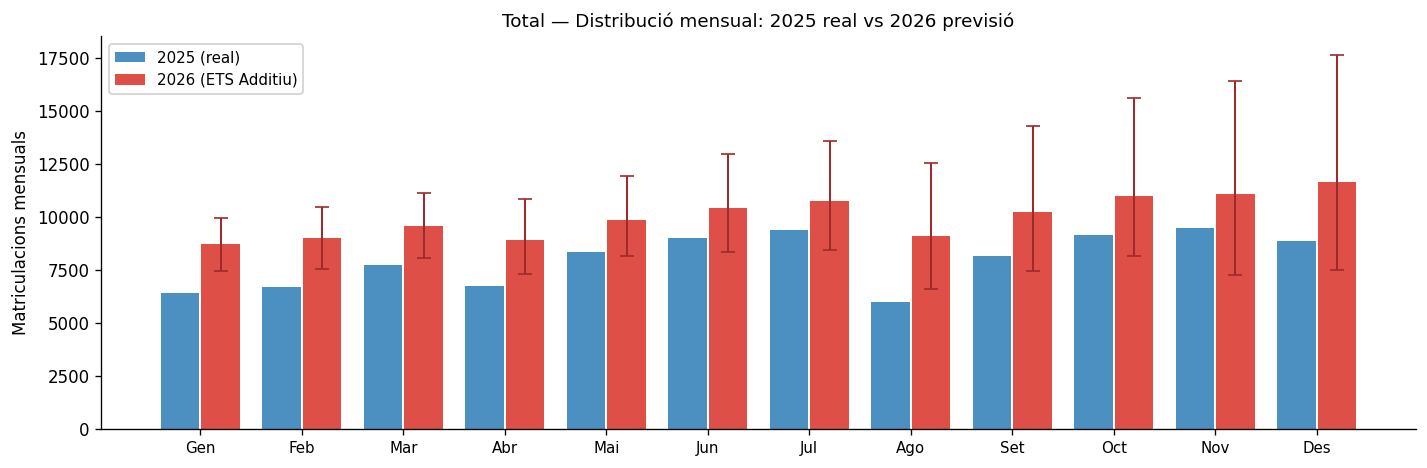

In [7]:
tech    = 'Total'
sub_tot = df_fc[df_fc['Tecnologia'] == tech].sort_values('date')
dates_tot = pd.to_datetime(sub_tot['date'])

# --- Gràfic 1: sèrie temporal amb IC ---
fig, ax = plt.subplots(figsize=(13, 5))
hist = pivot_full[tech].iloc[-48:]
ax.plot(hist.index, hist.values, color=COLOR_HIST, lw=2.2, label='Observat (historial)')
ax.axvline(pivot_full.index[-1], color='gray', ls=':', lw=1.2)
ax.plot(dates_tot, sub_tot['predicted'], color=COLOR_FC, lw=2,
        ls='--', marker='o', ms=5, label='ETS Additiu (previsió 2026)')
ax.fill_between(dates_tot, sub_tot['ci_lower'], sub_tot['ci_upper'],
                color=COLOR_FC, alpha=0.15, label='IC 95% (bootstrap)')
ax.axvspan(dates_tot.iloc[0], dates_tot.iloc[-1], alpha=0.06, color=COLOR_FC)

fc_sum    = sub_tot['predicted'].sum()
real_2025 = pivot_test[tech].sum()
yoy       = (fc_sum - real_2025) / real_2025 * 100
ax.set_title(
    f'Total — Previsió 2026: {fc_sum:.0f} unitats  (YoY 2025→2026: {yoy:+.1f}%)',
    fontsize=12)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_30_forecast_2026_total.png', bbox_inches='tight')
plt.show()

# --- Gràfic 2: barres mensuals 2025 vs 2026 ---
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(H)
ax.bar(x - 0.2, pivot_test[tech].values, width=0.38,
       color=COLOR_HIST, label='2025 (real)', alpha=0.85)
ax.bar(x + 0.2, sub_tot['predicted'].values, width=0.38,
       color=COLOR_FC, label='2026 (ETS Additiu)', alpha=0.85)
ax.errorbar(
    x + 0.2, sub_tot['predicted'].values,
    yerr=[sub_tot['predicted'].values - sub_tot['ci_lower'].values,
          sub_tot['ci_upper'].values - sub_tot['predicted'].values],
    fmt='none', color='#9e2a2b', capsize=4, lw=1.2)
ax.set_xticks(x)
ax.set_xticklabels(MONTHS_CA, fontsize=9)
ax.set_ylabel('Matriculacions mensuals')
ax.set_title('Total — Distribució mensual: 2025 real vs 2026 previsió', fontsize=11)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_31_forecast_2026_total_mensual.png', bbox_inches='tight')
plt.show()

---
## 5. Mix tecnològic 2021–2026

Com evoluciona la composició del mercat? Mostrem els volums anuals per tecnologia de 2021 a 2026 (les de 2026 són la previsió ETS Additiu) en dos formats: volums absoluts (barres apilades) i quotes de mercat (%). La sèrie 'Total' s'exclou per evitar doble comptatge.

> El 2026 s'indica amb asterisc per diferenciar la previsió de les dades reals.

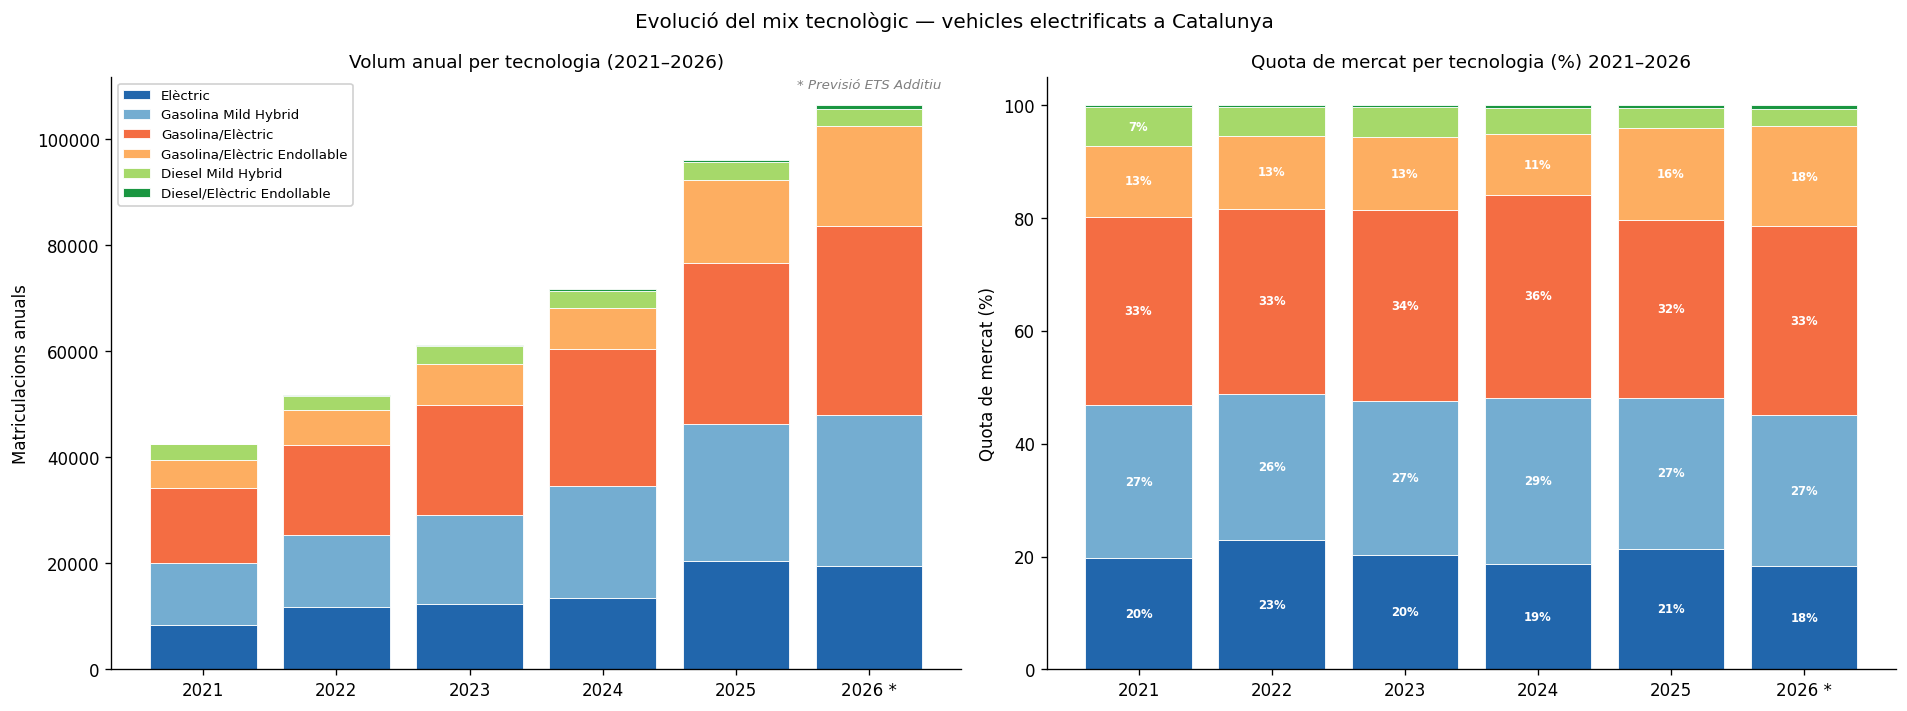

Quotes de mercat 2024 → 2025 → 2026:


,2024 (%),2025 (%),2026 (%)*
Elèctric,18.7,21.3,18.3
Gasolina Mild Hybrid,29.5,26.8,26.8
Gasolina/Elèctric,36.0,31.5,33.5
Gasolina/Elèctric Endollable,10.8,16.2,17.7
Diesel Mild Hybrid,4.6,3.5,3.2
Diesel/Elèctric Endollable,0.5,0.5,0.6


In [8]:
years_hist = [2021, 2022, 2023, 2024, 2025]
annual = {}
for year in years_hist:
    mask = pivot_full.index.year == year
    annual[year] = pivot_full.loc[mask, TECHS_NO_TOT].sum()

annual[2026] = (df_fc[df_fc['Tecnologia'].isin(TECHS_NO_TOT)]
                .groupby('Tecnologia')['predicted'].sum())

df_mix     = pd.DataFrame(annual).T[TECHS_NO_TOT]
df_mix_pct = df_mix.div(df_mix.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
years_labels = [str(y) + (' *' if y == 2026 else '') for y in df_mix.index]

# Barres apilades — volums absoluts
bottom = np.zeros(len(df_mix))
for tech in TECHS_NO_TOT:
    vals = df_mix[tech].values
    axes[0].bar(years_labels, vals, bottom=bottom,
                color=COLORS_TECH[tech], label=tech,
                edgecolor='white', linewidth=0.5)
    bottom += vals
axes[0].set_title('Volum anual per tecnologia (2021–2026)', fontsize=11)
axes[0].set_ylabel('Matriculacions anuals')
axes[0].legend(fontsize=8, loc='upper left', framealpha=0.9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].text(len(years_labels) - 1,
             df_mix.sum(axis=1).iloc[-1] * 1.03,
             '* Previsió ETS Additiu',
             ha='center', fontsize=8, style='italic', color='gray')

# Barres apilades — quotes (%)
bottom_pct = np.zeros(len(df_mix_pct))
for tech in TECHS_NO_TOT:
    vals = df_mix_pct[tech].values
    axes[1].bar(years_labels, vals, bottom=bottom_pct,
                color=COLORS_TECH[tech], label=tech,
                edgecolor='white', linewidth=0.5)
    for j, (v, b) in enumerate(zip(vals, bottom_pct)):
        if v > 6:
            axes[1].text(j, b + v / 2, f'{v:.0f}%',
                         ha='center', va='center',
                         fontsize=7, color='white', fontweight='bold')
    bottom_pct += vals
axes[1].set_title('Quota de mercat per tecnologia (%) 2021–2026', fontsize=11)
axes[1].set_ylabel('Quota de mercat (%)')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Evolució del mix tecnològic — vehicles electrificats a Catalunya',
             fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_32_forecast_2026_mix.png', bbox_inches='tight')
plt.show()

print('Quotes de mercat 2024 → 2025 → 2026:')
display(df_mix_pct.loc[[2024, 2025, 2026]].round(1).T
        .rename(columns={2024: '2024 (%)', 2025: '2025 (%)', 2026: '2026 (%)* '}))

---
## 6. Creixement interanual (YoY)

Taula comparativa de volums i taxes de creixement per a cada tecnologia: 2023 real → 2024 real → 2025 real → 2026 previsió. Permet veure si el model espera acceleració, desacceleració o estabilització per a cada segment del mercat.

In [9]:
yoy_rows = []
for tech in TECNOLOGIES:
    v2023 = pivot_full[tech][pivot_full.index.year == 2023].sum()
    v2024 = pivot_full[tech][pivot_full.index.year == 2024].sum()
    v2025 = pivot_test[tech].sum()
    v2026 = df_fc[df_fc['Tecnologia'] == tech]['predicted'].sum()

    def yoy(a, b):
        """YoY % arrodonit, evita l'artefacte -0.0 de coma flotant."""
        v = round((b - a) / a * 100, 1)
        return v + 0.0  # -0.0 → 0.0 en IEEE-754

    yoy_rows.append({
        'Tecnologia':    tech,
        '2023 (real)':   int(round(v2023)),
        '2024 (real)':   int(round(v2024)),
        '2025 (real)':   int(round(v2025)),
        '2026 (prev.)':  int(round(v2026)),
        'YoY 23→24 (%)': yoy(v2023, v2024),
        'YoY 24→25 (%)': yoy(v2024, v2025),
        'YoY 25→26 (%)': yoy(v2025, v2026),
    })

df_yoy = pd.DataFrame(yoy_rows).set_index('Tecnologia').loc[TECNOLOGIES]
print('Creixements interanuals per tecnologia:')
display(df_yoy)

Creixements interanuals per tecnologia:


,2023 (real),2024 (real),2025 (real),2026 (prev.),YoY 23→24 (%),YoY 24→25 (%),YoY 25→26 (%)
Tecnologia,,,,,,,
Elèctric,12394,13401,20495,19426,8.1,52.9,-5.2
Gasolina Mild Hybrid,16634,21135,25789,28476,27.1,22.0,10.4
Gasolina/Elèctric,20781,25810,30300,35600,24.2,17.4,17.5
Gasolina/Elèctric Endollable,7836,7739,15606,18849,-1.2,101.7,20.8
Diesel Mild Hybrid,3292,3281,3407,3385,-0.3,3.8,-0.6
Diesel/Elèctric Endollable,182,391,526,623,114.8,34.5,18.4
Total,61123,71760,96175,120504,17.4,34.0,25.3


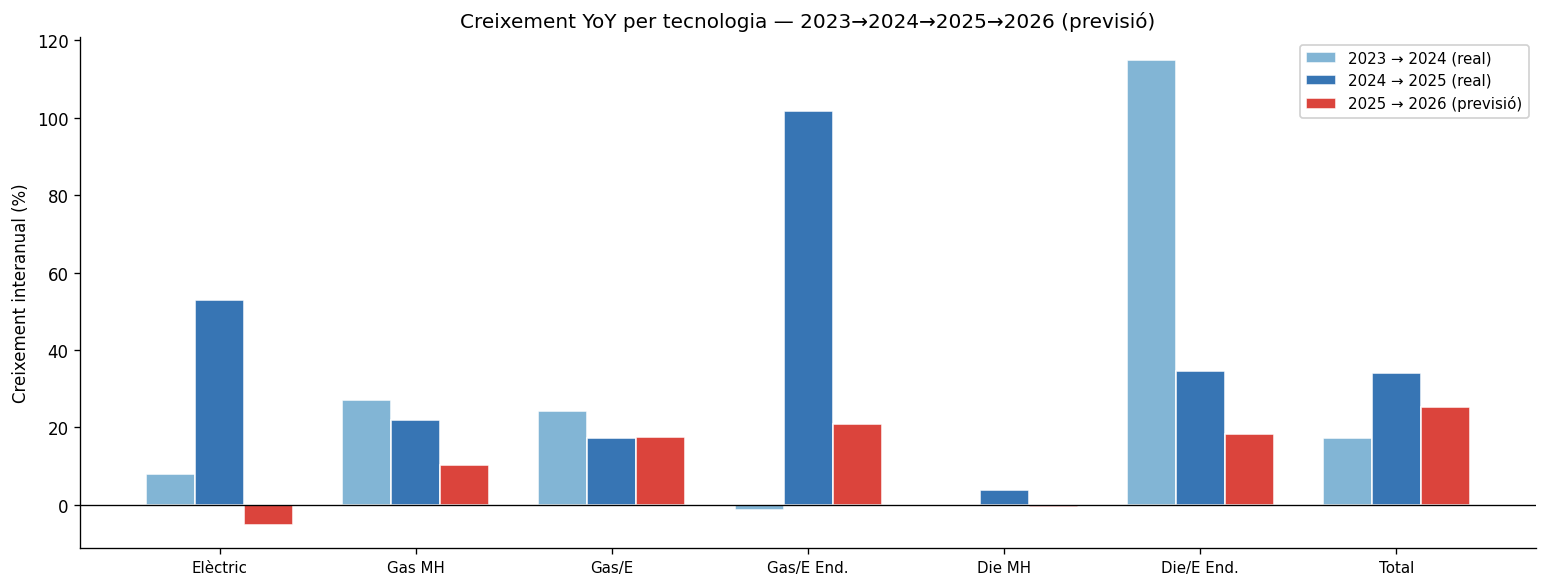

In [10]:
# Bar chart YoY: 3 columnes per tecnologia (23→24, 24→25, 25→26)
labels_short = ['Elèctric', 'Gas MH', 'Gas/E', 'Gas/E End.', 'Die MH', 'Die/E End.', 'Total']
yoy_cols   = ['YoY 23→24 (%)', 'YoY 24→25 (%)', 'YoY 25→26 (%)']
col_colors = ['#74add1', '#2166ac', '#d73027']
col_labels = ['2023 → 2024 (real)', '2024 → 2025 (real)', '2025 → 2026 (previsió)']
x = np.arange(len(TECNOLOGIES))
w = 0.25

fig, ax = plt.subplots(figsize=(13, 5))
for j, (col, color, label) in enumerate(zip(yoy_cols, col_colors, col_labels)):
    vals = df_yoy[col].values
    ax.bar(x + (j - 1) * w, vals, width=w,
           color=color, label=label, edgecolor='white', alpha=0.9)

ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels_short, fontsize=9)
ax.set_ylabel('Creixement interanual (%)')
ax.set_title('Creixement YoY per tecnologia — 2023→2024→2025→2026 (previsió)', fontsize=12)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_33_forecast_2026_yoy.png', bbox_inches='tight')
plt.show()

---
## 7. Conclusions

### Mercat total: +25.3% YoY → 120.504 unitats el 2026

El model prediu un mercat total de **120.504 matrícules** el 2026, enfront de les 96.175 reals del 2025 (+25.3% YoY). ETS Additiu per al Total té α=β=0.139 i γ=0.174 — absorbeix parcialment el creixement del 2025 i extrapola la tendència resultant. Atenció: el Total és modelat de forma independent; la suma de les 6 tecnologies individuals dóna ~ 106.400 unitats, la diferència (~ 14.100) correspon a les tecnologies esparses (Gas Mild Hybrid, Diesel/Elèctric) no modelades per separat.

### Resultats per tecnologia

| Tecnologia | 2025 (real) | 2026 (prev.) | YoY |
|---|---|---|---|
| Gasolina/Elèctric | 30.300 | **35.600** | +17.5% |
| Gasolina Mild Hybrid | 25.789 | **28.476** | +10.4% |
| Gas./Elèctric Endollable | 15.606 | **18.849** | +20.8% |
| **Elèctric** | 20.495 | **19.426** | **−5.2%** |
| Diesel/Elèctric Endollable | 526 | **623** | +18.4% |
| Diesel Mild Hybrid | 3.407 | **3.385** | −0.6% |
| **Total** | **96.175** | **120.504** | **+25.3%** |

Les tecnologies PHEV (Gasolina/Elèctric Endollable, +20.8%) i HEV plenes (Gasolina/Elèctric, +17.5%) són els motors principals del creixement. Gasolina Mild Hybrid (+10.4%) consolida la seva posició com la tecnologia de major volum individual. Diesel Mild Hybrid s'estabilitza (−0.6%).

### El cas Elèctric: −5.2% per α=β=γ=0

La predicció més contraintuïtiva és la d'Elèctric: **19.426 un. el 2026 vs 20.495 el 2025 (−5.2%)**. La causa no és una predicció de declivi del mercat elèctric, sinó una limitació del model: l'optimitzador convergeix a α=β=γ=0 per a Elèctric. Amb tots els paràmetres a zero, ETS treballa amb una tendència lineal i una estacionalitat fixos determinats per la descomposició inicial sobre 2017–2025, **sense actualitzar el nivell a partir de les observacions recents**. El salt de +52.9% del 2025 queda fora de la previsió, i el model retroba la trajectòria de fons (~19.000–20.000 un./any). Elèctric és el cas on el límit estructural d'ETS és més evident: per a sèries amb acceleració disruptiva i no lineal, caldria un model amb variables exògenes (preu dels EVs, xarxa de càrrega) o un ETS multiplicatiu.

### Patró estacional 2026 (sèrie Total)

El cicle mensual previst per al Total mostra: **pic fort al Q4** (oct: 11.006, nov: 11.094, **des: 11.673** — màxim de l'any) i pic secundari a l'estiu (jun: 10.424, jul: 10.764). **Mínim al gener** (8.738 un.). Aquest patró és coherent amb la dinàmica real de les matriculacions a Catalunya, on el desembre concentra el tancament d'objectius comercials anuals.

### Incertesa

Els intervals de confiança al 95% (bootstrap 500 simulacions) s'eixamplen progressivament: el desembre és el mes amb major amplada d'incertesa, reflectint que l'error s'acumula a mesura que ens allunyem del darrer punt observat (desembre 2025).

### Limitació principal

La previsió assumeix que el context d'incentius i preus del 2025 es manté el 2026. L'activació de noves convocatòries MOVES o canvis regulatoris europeus podrien alterar significativament les trajectòries. El cas Elèctric il·lustra fins a quin punt els models univariants queden curts davant de ruptures estructurals de mercat.

In [11]:
# Guardar resultats
df_fc.to_csv(RESULTS_DIR / 'forecast_2026.csv', index=False)
df_params.reset_index().to_csv(RESULTS_DIR / 'forecast_2026_ets_params.csv', index=False)
df_yoy.to_csv(RESULTS_DIR / 'forecast_2026_yoy.csv')
print('Guardats:')
print('  forecast_2026.csv            — prediccions mensuals 2026 + IC 95% (7 tecnologies)')
print('  forecast_2026_ets_params.csv — paràmetres α, β, γ, AIC, BIC per tecnologia')
print('  forecast_2026_yoy.csv        — volums anuals i YoY 2023–2026')

Guardats:
  forecast_2026.csv            — prediccions mensuals 2026 + IC 95% (7 tecnologies)
  forecast_2026_ets_params.csv — paràmetres α, β, γ, AIC, BIC per tecnologia
  forecast_2026_yoy.csv        — volums anuals i YoY 2023–2026
